# 05 · Extremes: RX1day, TXx and R95p

**Question for this notebook.** How well do the two EERIE models reproduce heavy-rainfall and
hot-day extremes over north-west Europe, and over the UK and Ireland in particular?

**Data.** Daily precipitation and daily maximum temperature, 1985–2014, on the north-west Europe
box (20°W–13°E, 40–65°N, 0.25° grid): ICON-ESM-ER r1, IFS-FESOM2-SR r1, the ERA5 reanalysis
reference, and E-OBS, a station-based gridded dataset that covers land only.

**Method** (fixed in `docs/methods.md` before any result was produced). Three standard indices,
each computed at every grid cell, once per calendar year and once per winter (December–February):

| Index | Plain meaning |
|---|---|
| **RX1day** | The wettest single day of the year (or winter), in mm. |
| **TXx** | The hottest day of the year (or winter): the highest daily maximum temperature, in °C. |
| **R95p** | How much rain fell on the *very wet* days of the year (or winter), in mm. A day is "very wet" if it exceeds the local 95th percentile of wet days (see Background). |

Annual indices are the general description of extremes. Winter indices exist because the next
notebook relates extremes to the *winter* NAO.

**Sections**
1. Setup and data check
2. Findings
3. RX1day: the wettest day of the year
4. R95p: rain on very wet days
5. TXx: the hottest day of the year
6. Winter versions of the indices
7. Regional numbers, land only
8. Year-to-year behaviour
9. Saved outputs
10. Limitations
11. What to check

## Background: the terms used in this notebook

If you know these already, skip to section 1.

| Term | What it means here |
|---|---|
| **Extreme index** | A single number per year that summarises the extreme end of daily weather, defined the same way everywhere so that datasets can be compared. These three come from the ETCCDI list used in IPCC reports. |
| **Wet day** | A day with at least 1 mm of precipitation. Days with less are treated as dry, because models tend to produce far too many days of drizzle. |
| **95th percentile of wet days** | The daily amount exceeded on only the wettest 5% of wet days at that place, over 1985–2014. It is a *local* threshold: about 15 mm in a dry region, 50 mm or more on a wet mountain coast. |
| **R95p** | The total rain that fell on days above that threshold, added up over the year. The whole day's rain is counted, not just the part above the threshold. Also shown as a share (%) of all wet-day rain. |
| **Base period** | The years used to define the threshold, here 1985–2014. Using the same years to define and to apply a threshold makes exceedances slightly less frequent than the nominal 5% (Zhang et al. 2005); this small effect is the same for every dataset and is not corrected. |
| **Winter (DJF)** | December–February, named after the year of its January. Winter 1985 has no December 1984 in the data, so there are 29 complete winters, 1986–2014. |
| **ERA5** | Reanalysis reference. Its temperature is well constrained by observations; its precipitation is produced by a weather model. |
| **E-OBS** | Daily maps built from weather-station measurements, land only. A more direct record of rainfall than ERA5, but station maps smooth out the most intense local rain, so E-OBS extremes tend to be on the low side. |
| **Land-only regional mean** | The average over the land grid cells of a region. Used for the headline numbers because extremes matter where people live and E-OBS has no data over sea. |
| **Percent difference** | 100 × (model − reference) ÷ reference. +30% means the model's value is 30% larger. |

**How to read the maps.** Maps of an index use one blue scale, light to dark. Difference maps use
blue–grey–orange: grey means no difference; the caption says which direction each colour is.
All panels of one figure share one colour scale.

**Colours of the lines.** Dark grey is ERA5, light grey is E-OBS, blue is ICON-ESM-ER, orange is
IFS-FESOM2-SR, as in every notebook of this project.

**What a 0.25° grid can and cannot show.** A grid cell is roughly 25 km across. Its "daily rainfall"
is an average over that area, so it is always lower than what a single rain gauge inside it could
record in a thunderstorm. All four datasets are compared on the same 0.25° grid.

> **Note on ERA5 daily data.** When this notebook was last run, the ERA5 *daily* files were not yet
> fully downloaded (the internet connection was too slow), so E-OBS is the only reference here.
> E-OBS is the more direct reference for extremes over land in any case. The notebook picks up
> ERA5 automatically, as a second reference, once `data/era5/day/` holds all 30 years: just run it again.

## 1. Setup and data check

**What this cell does.** Loads the project code. The index definitions are in
`eerie_uk/extremes.py`; each has a unit test on a small made-up series with a known answer.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path
from eerie_uk import climatology as clim, extremes as ex, plotting, regions, store

pd.set_option('display.width', 220, 'display.float_format', '{:.1f}'.format)
MODELS = ['icon-esm-er', 'ifs-fesom2-sr']
REFS = ['e-obs']      # reference datasets
SOURCES = REFS + MODELS
NAME = plotting.SOURCE_LABELS

**What this cell does.** Confirms the daily downloads are complete: for each source and variable,
the first and last year, the number of yearly files and any gaps. Thirty files and an empty `gaps`
column are required before the indices mean anything.

In [2]:
inventory = store.available()
daily = inventory[inventory.frequency == 'day'].reset_index(drop=True)
daily

,source,frequency,variable,box,first,last,years,gaps,MB
0,e-obs,day,pr,nw_europe,1985,2014,30,,73.2
1,e-obs,day,tasmax,nw_europe,1985,2014,30,,135.5
2,era5,day,pr,nw_europe,1985,1993,9,,130.9
3,icon-esm-er,day,pr,nw_europe,1985,2014,30,,496.7
4,icon-esm-er,day,tasmax,nw_europe,1985,2014,30,,329.0
5,ifs-fesom2-sr,day,pr,nw_europe,1985,2014,30,,447.7
6,ifs-fesom2-sr,day,tasmax,nw_europe,1985,2014,30,,329.0


**What this cell does.** Computes all indices for each source: the local 95th-percentile threshold,
then RX1day, R95p, the R95p share and TXx, per year and per winter. The first run reads about
11,000 daily maps per variable and takes about a minute per source; the result is saved under
`data/derived/` so later runs are instant.

In [3]:
indices = {s: ex.indices_for(s) for s in SOURCES}
pd.DataFrame([{'source': NAME[s], 'years': indices[s].sizes['year_ann'], 'winters': indices[s].sizes['year_djf'],
               'grid (lat x lon)': f"{indices[s].sizes['lat']} x {indices[s].sizes['lon']}",
               'cells with data %': 100 * float(indices[s].rx1day_ann.isel(year_ann=0).notnull().mean())} for s in SOURCES])

,source,years,winters,grid (lat x lon),cells with data %
0,E-OBS,30,29,100 x 132,32.7
1,ICON-ESM-ER,30,29,101 x 133,100.0
2,IFS-FESOM2-SR,30,29,101 x 133,100.0


**What this cell does.** Puts E-OBS on the same grid points as the models. E-OBS uses a 0.25° grid
shifted by half a cell, so its index maps are interpolated (bilinearly) to the model grid. It also
builds a land mask from the Natural Earth coastline, for the land-only averages, and keeps the
land cells where E-OBS has data as the common set used for all regional numbers.

In [4]:
grid = indices['icon-esm-er']
indices['e-obs'] = regions.to_grid(indices['e-obs'], grid)
land = regions.land_mask(grid.lat, grid.lon)
observed = indices['e-obs'].rx1day_ann.isel(year_ann=0).notnull() & indices['e-obs'].txx_ann.isel(year_ann=0).notnull()
common = land & observed      # the same cells are used for every dataset in regional averages
print(f'land cells: {int(land.sum())} of {land.size} ({100 * float(land.mean()):.0f}%); land cells with E-OBS data: {int(common.sum())}')

def mean_map(source, name):
    'Average of an index over all its years.'
    field = indices[source][name]
    return field.mean([d for d in field.dims if d.startswith('year')])

def percent_difference(a, b):
    return 100 * (a - b) / b

land cells: 4446 of 13433 (33%); land cells with E-OBS data: 3735


## 2. Findings

Numbers are 1985–2014 averages over UK and Ireland land, each model against E-OBS (station-based). One member per model. ERA5 daily data were not yet available for this run (see the note above), so E-OBS is the only reference.

| UK and Ireland, land | E-OBS | ICON-ESM-ER | IFS-FESOM2-SR |
|---|---|---|---|
| **Wettest day of the year (RX1day)** | 30.9 mm | 45.7 mm (**+48%**) | 33.4 mm (+8%) |
| **Rain on very wet days per year (R95p)** | 181 mm | 274 mm (**+52%**) | 196 mm (+9%) |
| Share of rain that falls on very wet days | 17.7% | 19.8% | 19.1% |
| **Hottest day of the year (TXx)** | 26.9 °C | 23.6 °C (**−3.3 °C**) | 25.0 °C (−1.9 °C) |
| Wettest winter day | 21.9 mm | 29.1 mm (+33%) | 23.9 mm (+9%) |
| Rain on very wet winter days | 49 mm | 79 mm (+62%) | 53 mm (+9%) |
| Mildest winter day | 12.9 °C | 11.6 °C (−1.3 °C) | 11.7 °C (−1.2 °C) |

**What this means, in plain words**

1. **The data are complete for both models and E-OBS:** 30 years of daily files each, no gaps, 29 complete winters.
2. **IFS-FESOM2-SR's rainfall extremes are close to E-OBS.** Its wettest day and its very-wet-day rainfall are within about 10% over UK and Ireland, in both the year and the winter, and within a few percent in north-west France. A model being slightly wetter than E-OBS is expected, because station-based maps smooth intense rain.
3. **ICON-ESM-ER's rainfall extremes are much too heavy:** roughly +50% for the year and +30% to +60% in winter, in all three regions. This goes beyond what E-OBS smoothing could explain, and it continues the pattern seen earlier: too-strong westerlies (notebook 03), a mean state like a permanent positive NAO (notebook 04), too much winter rain on average (+39%), and now too-heavy extremes. The excess is also present in north-west France and in summer-dominated annual maxima, so the circulation bias is probably not the whole story.
4. **The share of rain falling on very wet days is similar in all three** (18–20%). ICON-ESM-ER therefore rains too much on ordinary and on extreme days alike, more than it rains in the wrong *way*.
5. **Both models' hottest days are too cool compared with E-OBS,** by about 3 °C in ICON-ESM-ER and 2 °C in IFS-FESOM2-SR over UK and Ireland, and by up to 5 °C in north-west France. A check of the underlying data shows why this is not just about rare hot days: the *average* summer daily maximum is already about 2 °C lower than E-OBS in both models (17.6 and 17.7 °C against 19.6 °C, 1995–2004), although their average summer temperature is within 1 °C of ERA5. So the models' days do not warm up as much in the afternoon as the station record says. Part of this may be a fair-comparison problem and not a model fault: a 25 km grid cell near a coast or on high ground is cooler than the low-lying stations behind E-OBS. ERA5 daily maxima, once downloaded, will help to separate the two. Cool hot extremes are consistent across the two models examined.
6. **Year-to-year spread** of the regional extremes is of the right order in both models. ICON-ESM-ER's hottest day varies less from year to year than E-OBS's (about 1.0 °C against 1.6 °C), in line with its low temperature variability in notebook 03.

**Bottom line.** For rainfall extremes IFS-FESOM2-SR is credible and ICON-ESM-ER is clearly too wet. For hot extremes both models are too cool relative to station-based data, with an open question about how much of that is the comparison itself. These are exploratory results.

## 3. RX1day: the wettest day of the year

**What this cell does.** Maps the average annual RX1day for the four sources: at each place, the
wettest day of each year, averaged over the 30 years.

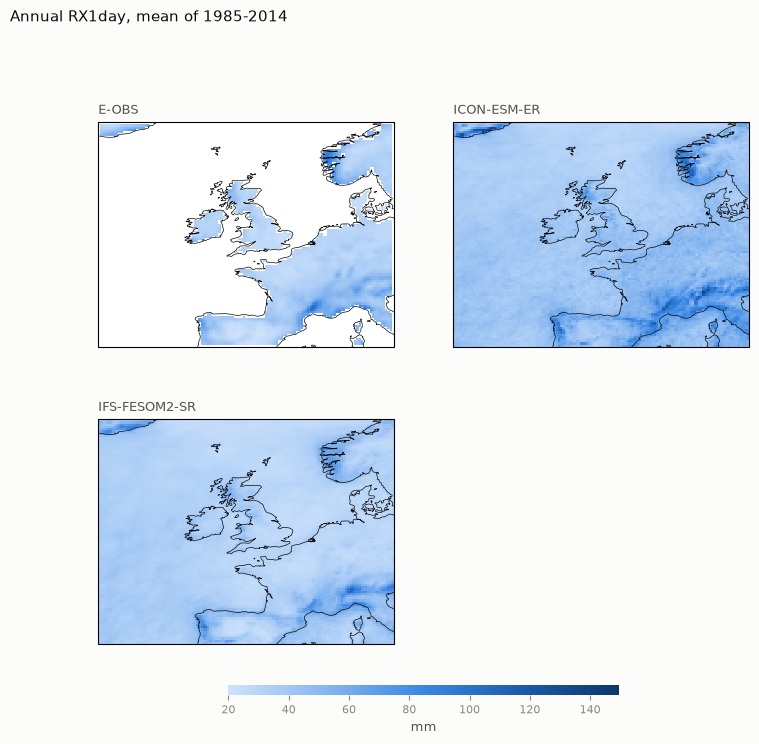

In [5]:
plotting.plot_field_panels({NAME[s]: mean_map(s, 'rx1day_ann') for s in SOURCES}, units='mm',
                           title='Annual RX1day, mean of 1985-2014', columns=2);

**Figure 1.** Average wettest day of the year. The largest values should follow mountains facing
the Atlantic and the Mediterranean (western Norway, western Scotland, north-west Iberia, the Alps
and the Cévennes). E-OBS is blank over sea.

**What this cell does.** Shows each model's RX1day as a percent difference from each reference
dataset (one row of maps per reference).

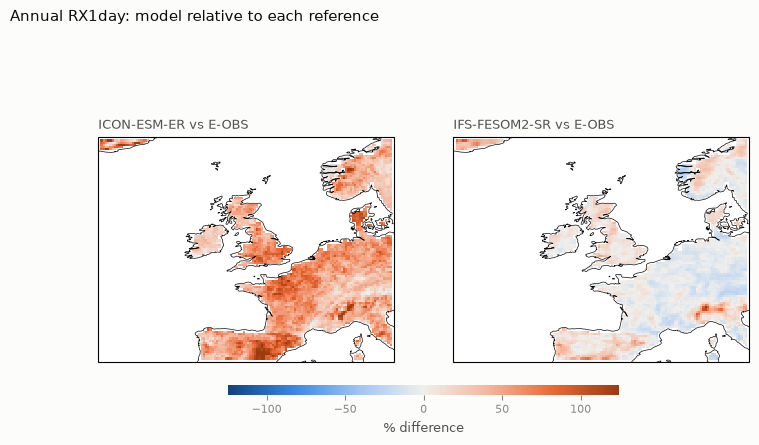

In [6]:
panels = {f'{NAME[m]} vs {NAME[r]}': percent_difference(mean_map(m, 'rx1day_ann'), mean_map(r, 'rx1day_ann'))
          for r in REFS for m in MODELS}
plotting.plot_field_panels(panels, units='% difference', title='Annual RX1day: model relative to each reference', columns=2, diverging=True);

**Figure 2.** RX1day percent difference. Orange: the model's wettest day is wetter than the
reference; blue: drier. E-OBS smooths intense rain, so a model that is somewhat wetter than E-OBS is not
necessarily wrong.

## 4. R95p: rain on very wet days

**What this cell does.** Maps the local threshold that defines a "very wet day" in each source:
the 95th percentile of wet-day precipitation. This is worth seeing first, because R95p is measured
against each dataset's *own* threshold.

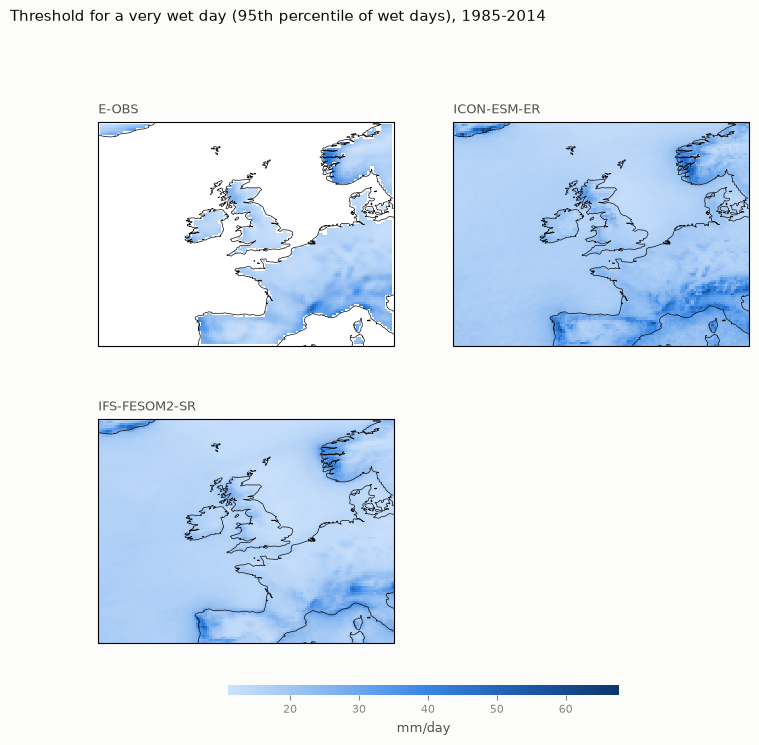

In [7]:
plotting.plot_field_panels({NAME[s]: indices[s].p95_ann for s in SOURCES}, units='mm/day',
                           title='Threshold for a very wet day (95th percentile of wet days), 1985-2014', columns=2);

**Figure 3.** The very-wet-day threshold. A model with a higher threshold than the references has
heavier heavy-rain days.

**What this cell does.** Maps the average annual R95p (mm of rain per year that falls on very wet
days) for the four sources.

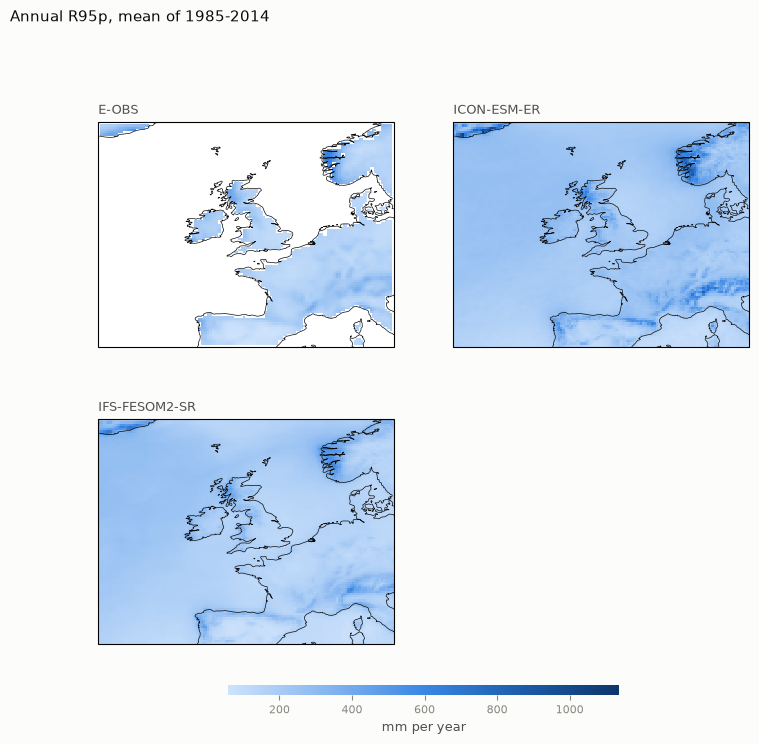

In [8]:
plotting.plot_field_panels({NAME[s]: mean_map(s, 'r95p_ann') for s in SOURCES}, units='mm per year',
                           title='Annual R95p, mean of 1985-2014', columns=2);

**Figure 4.** Rain falling on very wet days, per year. It is large where it rains a lot overall, so
it resembles a map of total rainfall; the next figure removes that effect.

**What this cell does.** Maps R95p as a share of all wet-day rain. This says how *concentrated*
the rain is in heavy days, independent of how wet the place is.

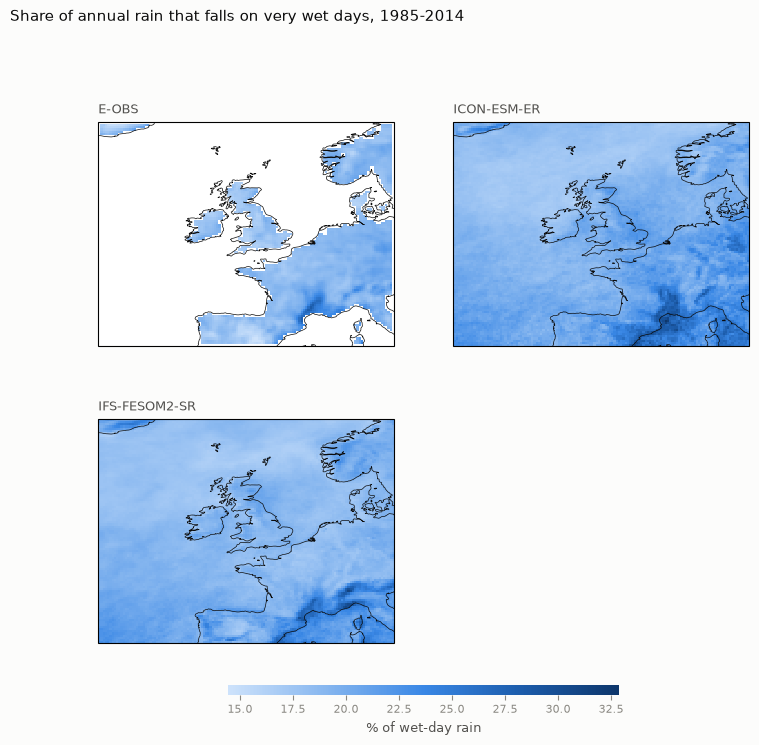

In [9]:
plotting.plot_field_panels({NAME[s]: mean_map(s, 'r95p_share_ann') for s in SOURCES}, units='% of wet-day rain',
                           title='Share of annual rain that falls on very wet days, 1985-2014', columns=2);

**Figure 5.** Share of rain from very wet days. By construction it sits near 15–25% almost
everywhere, so differences between panels are subtle; it is higher where rain comes in a few
intense events (around the Mediterranean) and lower in steady maritime climates.

## 5. TXx: the hottest day of the year

**What this cell does.** Maps the average annual TXx for the four sources.

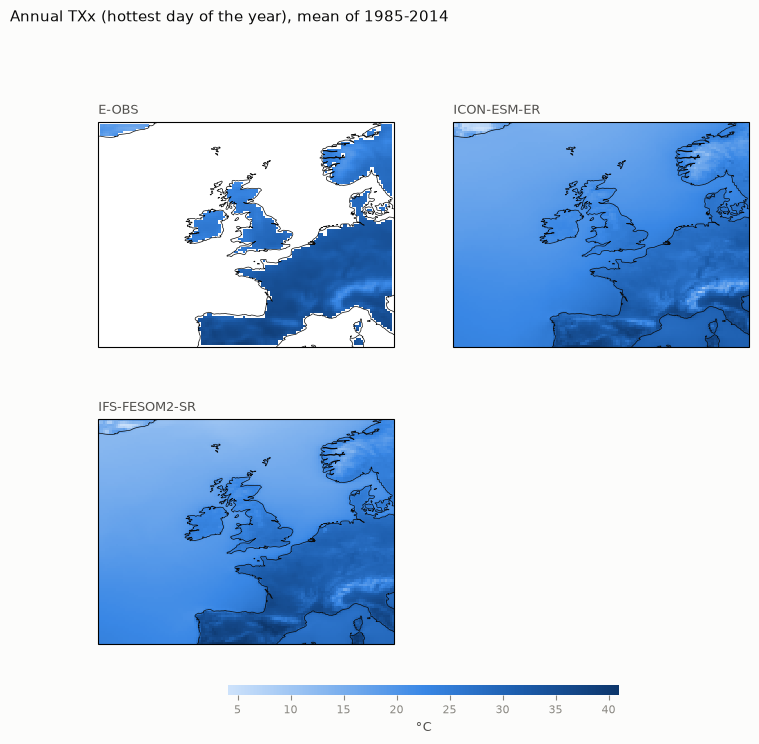

In [10]:
plotting.plot_field_panels({NAME[s]: mean_map(s, 'txx_ann') for s in SOURCES}, units='°C',
                           title='Annual TXx (hottest day of the year), mean of 1985-2014', columns=2);

**Figure 6.** Average hottest day of the year. Over sea the hottest day is far cooler than over
land, which is why headline numbers are land-only.

**What this cell does.** Shows each model's TXx minus each reference dataset, in °C.

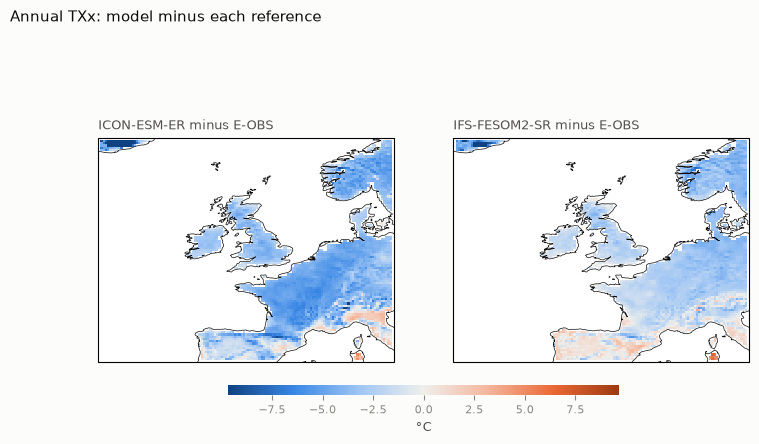

In [11]:
panels = {f'{NAME[m]} minus {NAME[r]}': mean_map(m, 'txx_ann') - mean_map(r, 'txx_ann')
          for r in REFS for m in MODELS}
plotting.plot_field_panels(panels, units='°C', title='Annual TXx: model minus each reference', columns=2, diverging=True);

**Figure 7.** TXx difference. Orange: the model's hottest day is hotter than the reference; blue:
cooler. Sharp spots over mountains partly reflect different terrain heights.

## 6. Winter versions of the indices

The same indices restricted to December–February, 29 winters (1986–2014). These are the quantities
the next notebook relates to the winter NAO.

**What this cell does.** Maps the average winter RX1day (wettest winter day) for the four sources.

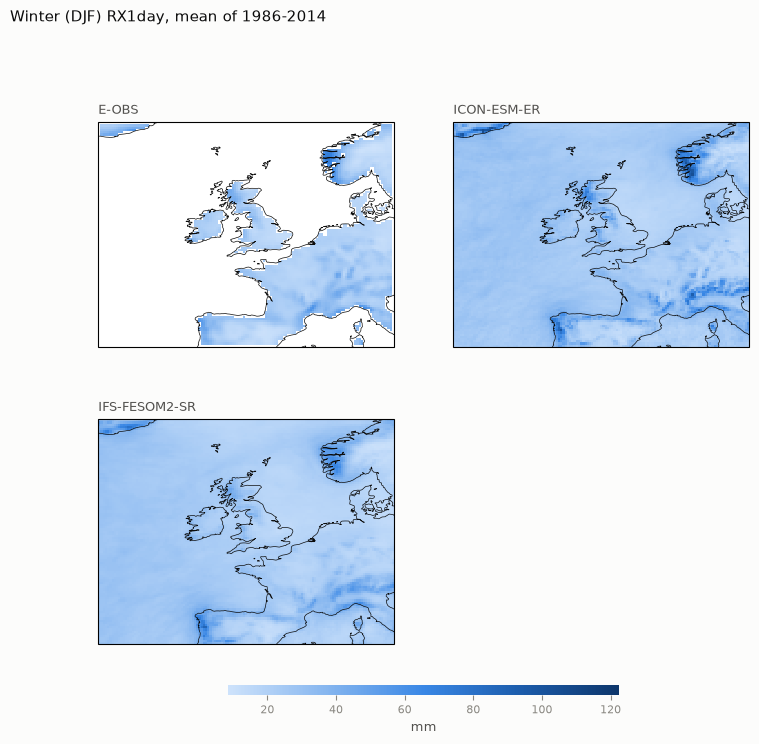

In [12]:
plotting.plot_field_panels({NAME[s]: mean_map(s, 'rx1day_djf') for s in SOURCES}, units='mm',
                           title='Winter (DJF) RX1day, mean of 1986-2014', columns=2);

**Figure 8.** Average wettest winter day. In winter the heaviest rain is brought by Atlantic
storms, so the maximum sits on west-facing coasts and mountains.

**What this cell does.** Maps the average winter R95p for the four sources.

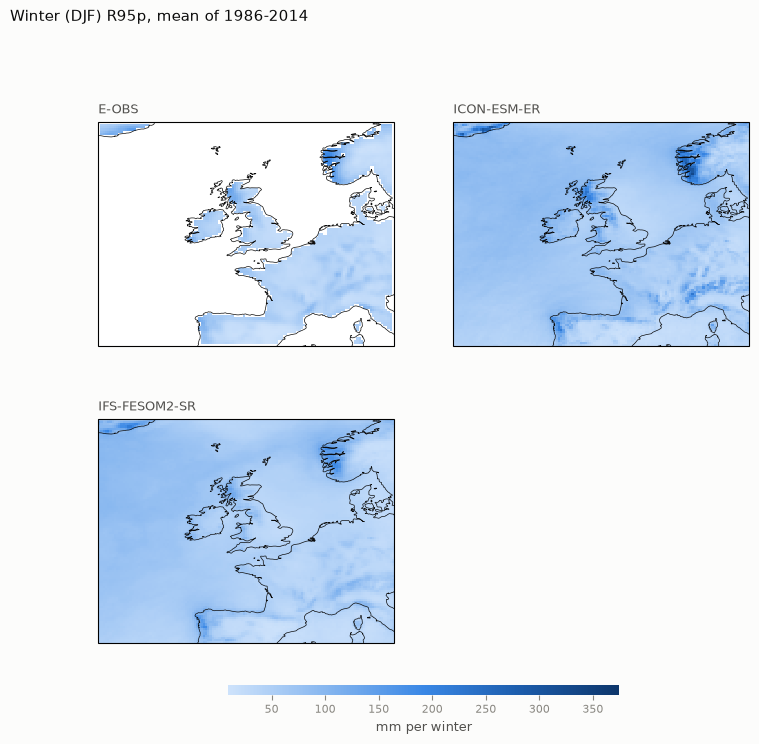

In [13]:
plotting.plot_field_panels({NAME[s]: mean_map(s, 'r95p_djf') for s in SOURCES}, units='mm per winter',
                           title='Winter (DJF) R95p, mean of 1986-2014', columns=2);

**Figure 9.** Rain on very wet winter days. The winter threshold is computed from winter days only.

**What this cell does.** Maps the average winter TXx (the mildest winter day) for the four sources.

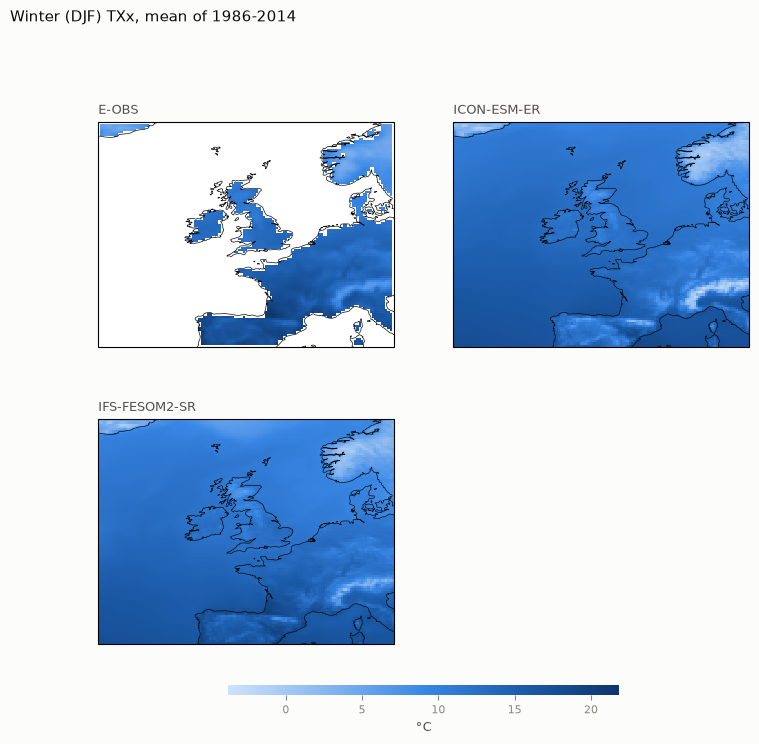

In [14]:
plotting.plot_field_panels({NAME[s]: mean_map(s, 'txx_djf') for s in SOURCES}, units='°C',
                           title='Winter (DJF) TXx, mean of 1986-2014', columns=2);

**Figure 10.** The warmest winter day. This is a mild-spell measure, not a heat extreme; it is
included because mild, wet, windy winters are the signature of a positive NAO.

## 7. Regional numbers, land only

UK and Ireland is the headline region. Western Norway and north-west France are supporting regions
on the wet and dry sides of the NAO rainfall pattern.

**What this cell does.** Averages each index over the land cells of each region, for every year.
Exactly the same cells are used for every dataset (land cells where E-OBS has data), so coastal
cells that are partly sea in one dataset cannot distort the comparison. It then
and collects the results in one long table (`series`) used for the tables and charts below and
saved for the next notebook.

In [15]:
INDEX_LABELS = {'rx1day': 'RX1day (mm)', 'r95p': 'R95p (mm)', 'r95p_share': 'R95p share (%)', 'txx': 'TXx (°C)'}
rows = []
for s in SOURCES:
    for tag, period in (('ann', 'annual'), ('djf', 'winter')):
        for key in INDEX_LABELS:
            field = indices[s][f'{key}_{tag}'].where(common).rename({f'year_{tag}': 'year'})
            for r in regions.SUBREGIONS:
                values = clim.regional_mean(field, r)
                rows += [{'source': s, 'region': r, 'period': period, 'index': key, 'year': int(y), 'value': float(v)}
                         for y, v in zip(values.year.values, values.values)]
series = pd.DataFrame(rows)
print(len(series), 'regional values')

2124 regional values


**What this cell does.** The headline table: the 30-year (or 29-winter) average of each index over
UK and Ireland land, for all four sources, with each model's difference from both references.
Differences are in % for the rainfall indices and in °C for TXx.

In [16]:
def headline(region):
    mean = series[series.region == region].groupby(['period', 'index', 'source']).value.mean().unstack('source')[SOURCES]
    out = mean.rename(columns=NAME)
    for m in MODELS:
        for r in REFS:
            relative = 100 * (mean[m] - mean[r]) / mean[r]
            absolute = mean[m] - mean[r]
            is_temperature = mean.index.get_level_values('index') == 'txx'
            out[f'{NAME[m]} vs {NAME[r]}'] = np.where(is_temperature, absolute, relative)
    out.index = pd.MultiIndex.from_tuples([(p, INDEX_LABELS[i]) for p, i in out.index], names=['period', 'index'])
    return out
uk = headline('uk_ireland')
uk

source                 E-OBS  ICON-ESM-ER  IFS-FESOM2-SR  ICON-ESM-ER vs E-OBS  IFS-FESOM2-SR vs E-OBS
period index                                                                                          
annual R95p (mm)       180.5        274.0          196.1                  51.8                     8.6
       R95p share (%)   17.7         19.8           19.1                  11.7                     7.7
       RX1day (mm)      30.9         45.7           33.4                  47.8                     8.0
       TXx (°C)         26.9         23.6           25.0                  -3.3                    -1.9
winter R95p (mm)        48.8         78.9           53.2                  61.6                     9.0
       R95p share (%)   15.6         16.4           16.2                   5.0                     3.4
       RX1day (mm)      21.9         29.1           23.9                  33.2                     9.3
       TXx (°C)         12.9         11.6           11.7                  -1.3                    -1.2

**What this cell does.** The same table for the two supporting regions.

In [17]:
pd.concat({regions.LABELS[r]: headline(r) for r in ('western_norway', 'nw_france')})

source                                   E-OBS  ICON-ESM-ER  IFS-FESOM2-SR  ICON-ESM-ER vs E-OBS  IFS-FESOM2-SR vs E-OBS
                  period index                                                                                          
Western Norway    annual R95p (mm)       338.2        519.8          355.6                  53.7                     5.1
                         R95p share (%)   18.9         19.0           20.1                   0.7                     6.7
                         RX1day (mm)      52.8         68.5           51.4                  29.8                    -2.5
                         TXx (°C)         23.0         19.1           19.6                  -3.8                    -3.4
                  winter R95p (mm)        97.7        166.2          112.2                  70.1                    14.8
                         R95p share (%)   15.6         15.8           17.8                   1.6                    14.2
                         RX1day (mm)      39.3         55.7           43.3                  41.9                    10.3
                         TXx (°C)          6.8          3.3            3.6                  -3.4                    -3.1
North-west France annual R95p (mm)       141.8        241.5          143.3                  70.3                     1.1
                         R95p share (%)   18.5         21.0           18.5                  13.7                     0.4
                         RX1day (mm)      29.8         49.6           29.2                  66.6                    -1.8
                         TXx (°C)         33.7         28.8           31.9                  -4.9                    -1.8
                  winter R95p (mm)        38.9         62.2           41.9                  60.0                     7.9
                         R95p share (%)   17.3         16.6           16.9                  -4.1                    -2.0
                         RX1day (mm)      20.9         26.0           22.0                  24.3                     5.2
                         TXx (°C)         16.0         13.0           14.4                  -2.9                    -1.5

## 8. Year-to-year behaviour

A model and the real world do not share the same sequence of years, so the lines below are not
expected to rise and fall together. Compare their level and how much they vary.

**What this cell does.** Plots annual RX1day (land average) for each year, in the three regions.

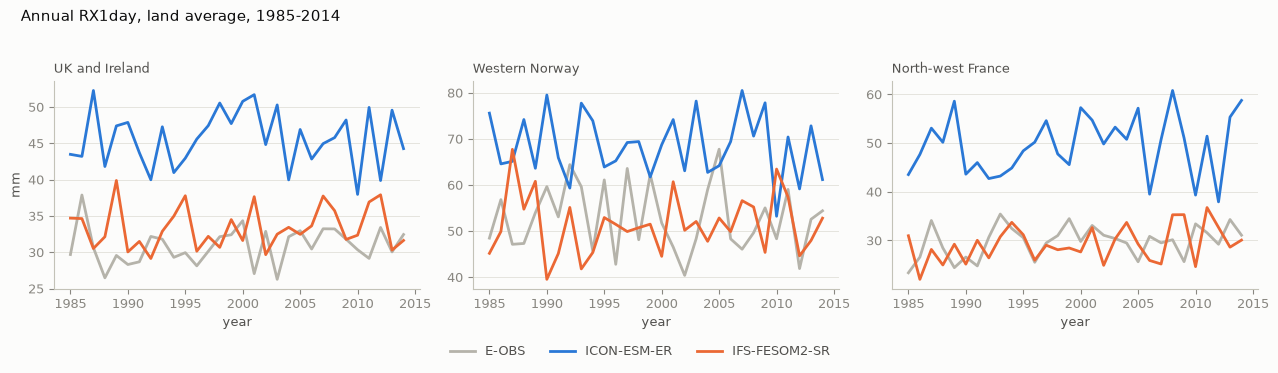

In [18]:
def series_panels(index, period):
    panels = {}
    for r in regions.SUBREGIONS:
        part = series[(series.region == r) & (series['index'] == index) & (series.period == period)]
        panels[regions.LABELS[r]] = {s: (part[part.source == s].year.values, part[part.source == s].value.values) for s in SOURCES}
    return panels
plotting.plot_line_panels(series_panels('rx1day', 'annual'), ylabel='mm', xlabel='year', title='Annual RX1day, land average, 1985-2014');

**Figure 11.** Wettest day of each year, averaged over the land of each region.

**What this cell does.** The same for annual TXx.

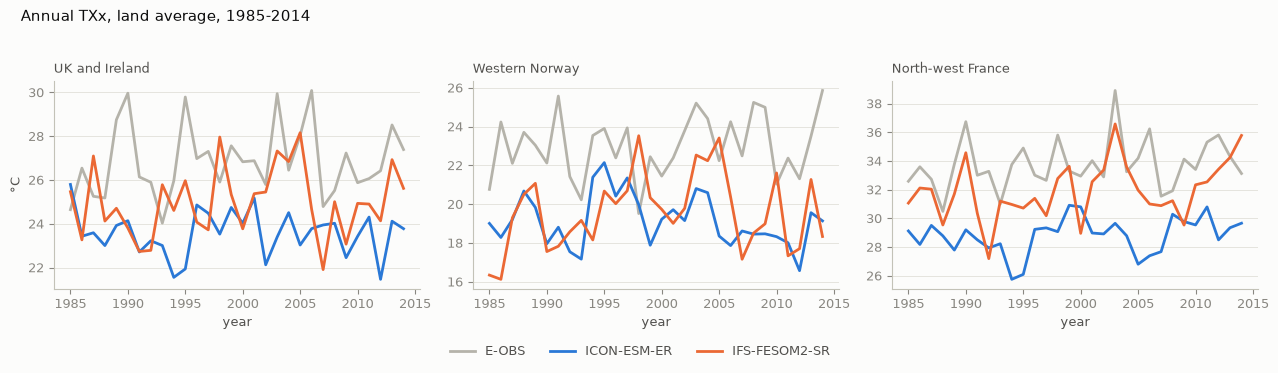

In [19]:
plotting.plot_line_panels(series_panels('txx', 'annual'), ylabel='°C', xlabel='year', title='Annual TXx, land average, 1985-2014');

**Figure 12.** Hottest day of each year, land average. ERA5 and E-OBS describe the same real years
and should move together (2003 and 2006 were hot summers in western Europe); that agreement is a
check on the two references.

**What this cell does.** The same for winter R95p, one of the quantities used in the next notebook.

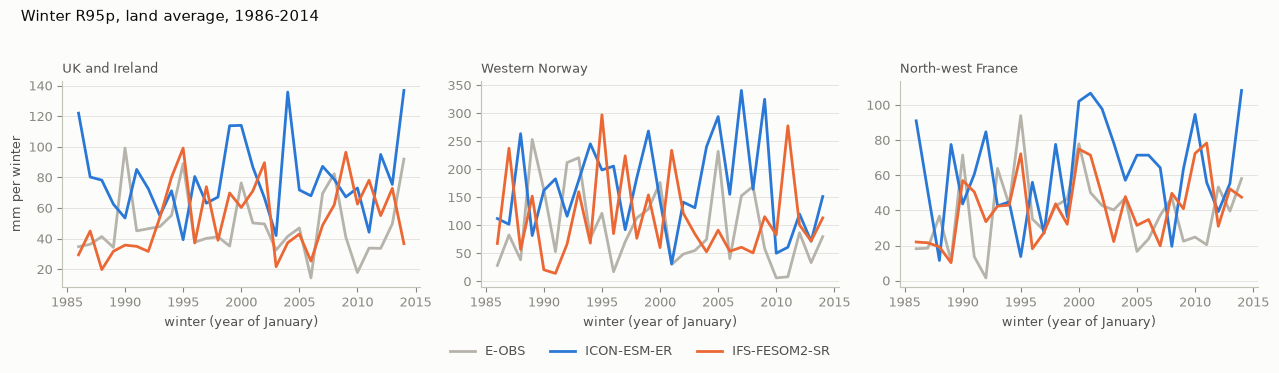

In [20]:
plotting.plot_line_panels(series_panels('r95p', 'winter'), ylabel='mm per winter', xlabel='winter (year of January)', title='Winter R95p, land average, 1986-2014');

**Figure 13.** Rain on very wet winter days, land average.

**What this cell does.** Summarises the year-to-year spread: the standard deviation of each regional
series for UK and Ireland, per source. A model whose spread is far from both references has
extremes that vary too much or too little from year to year.

In [21]:
spread = series[series.region == 'uk_ireland'].groupby(['period', 'index', 'source']).value.std().unstack('source')[SOURCES].rename(columns=NAME)
spread.index = pd.MultiIndex.from_tuples([(p, INDEX_LABELS[i]) for p, i in spread.index], names=['period', 'index'])
spread

source                 E-OBS  ICON-ESM-ER  IFS-FESOM2-SR
period index                                            
annual R95p (mm)        36.5         46.0           34.4
       R95p share (%)    2.4          2.1            2.5
       RX1day (mm)       2.5          3.9            2.9
       TXx (°C)          1.6          1.0            1.6
winter R95p (mm)        21.1         25.3           22.7
       R95p share (%)    3.8          3.2            5.0
       RX1day (mm)       2.4          3.1            3.9
       TXx (°C)          0.9          0.7            0.8

## 9. Saved outputs

**What this cell does.** Saves the regional series as a small Parquet table in `app_assets/`, for
the NAO-to-extremes notebook and the dashboard. The gridded indices are already cached under
`data/derived/`.

In [22]:
out = Path('../app_assets'); out.mkdir(exist_ok=True)
series.to_parquet(out / 'extremes_regional.parquet', index=False)
print(len(series), 'rows saved to app_assets/extremes_regional.parquet')

2124 rows saved to app_assets/extremes_regional.parquet


## 10. Limitations

- **One member per model and 30 years.** A 30-year mean of an annual maximum is still noisy,
  especially for rainfall. Differences of 10% or so in RX1day at a single grid cell mean little.
- **Neither reference is the truth for rainfall extremes.** ERA5 rain is a model product at about
  31 km. E-OBS is built from stations and smooths intense local rain, more so where stations are
  sparse. The models are compared with both, and a conclusion is firm only where both agree.
- **Grid-cell values are area averages** (about 25 km), lower than point measurements.
- **ERA5 and E-OBS were interpolated** to the model grid bilinearly. For precipitation a conservative
  method would be preferable; bilinear interpolation slightly smooths maxima.
- **Terrain heights differ** between datasets, which affects TXx over mountains.
- **In-base percentile effect** (see Background): small and common to all datasets.
- **Annual TXx is a summer quantity** and is not related to the winter NAO.
- **29 winters,** not 30, because the first winter lacks its December.

## 11. What to check

1. **Section 1 tables:** 30 yearly files and no gaps for every source and variable.
2. **Figures 1–2:** is the pattern of RX1day credible, and is the model difference from the two
   references acceptable for a prototype?
3. **Figure 7:** the same question for TXx.
4. **The UK and Ireland table:** these are the headline numbers. Do you want a different region or
   an additional index?
5. **Go for day 5:** the NAO-to-extremes notebook, the centrepiece.